# Earthquake Analysis

Mihera Gaikee B2-B1-13

Jidnyasa Zade B2-B1-09

**Goal:** Use Spark to analyze 100+ years of global earthquake data and find out which regions get hit most often and hardest, plus check frequency trends and any depth-magnitude relationship.

cleaning the dataset

In [ ]:
import pandas as pd

df = pd.read_csv("earthquakes.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values per column:\n", df.isnull().sum())

Shape: (115983, 23)
Columns: ['Unnamed: 0', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource']
Missing values per column:
 Unnamed: 0             0
time                   0
latitude               0
longitude              0
depth                285
mag                    0
magType                0
nst                70645
gap                60364
dmin               80308
rms                28747
net                    0
id                     0
updated                0
place                891
type                   0
horizontalError    81685
depthError         49715
magError           67080
magNst             60036
status                 0
locationSource         0
magSource              0
dtype: int64


In [ ]:
# keep only relevant columns
df_clean = df[['time', 'latitude', 'longitude', 'depth', 'mag', 'place', 'type']]

# Keep only actual earthquakes (dataset may include explosions, quarry blasts, etc.)
df_clean = df_clean[df_clean['type'] == 'earthquake']

print("Shape after filtering type:", df_clean.shape)
print("Unique types were:", df['type'].unique())

Shape after filtering type: (115487, 7)
Unique types were: ['earthquake' 'nuclear explosion' 'explosion' 'rock burst' 'mine collapse'
 'volcanic eruption' 'landslide']


In [ ]:
df_clean = df_clean.dropna(subset=['depth', 'place'])

df_clean['time'] = pd.to_datetime(df_clean['time'])
df_clean['year'] = df_clean['time'].dt.year

print("Shape after dropping nulls:", df_clean.shape)
print(df_clean[['time', 'year']].head())

Shape after dropping nulls: (114311, 8)
                               time  year
16 1904-04-04 10:26:00.880000+00:00  1904
17 1904-04-04 10:02:34.560000+00:00  1904
18 1904-06-25 21:00:38.720000+00:00  1904
19 1904-06-25 14:45:39.140000+00:00  1904
20 1904-08-30 11:43:20.850000+00:00  1904


In [ ]:
# Extract region from 'place'
def extract_region(place):
    if ',' in place:
        return place.split(',')[-1].strip()
    return place.strip()

df_clean['region'] = df_clean['place'].apply(extract_region)

print("Number of unique regions:", df_clean['region'].nunique())
print(df_clean['region'].value_counts().head(10))

Number of unique regions: 528
region
Indonesia                        13020
Japan                             7009
Papua New Guinea                  6951
Russia                            6089
Philippines                       5667
Tonga                             4672
Alaska                            4339
Vanuatu                           3685
Chile                             3572
South Sandwich Islands region     2723
Name: count, dtype: int64


installing spark

In [ ]:
!pip install pyspark

from pyspark import SparkContext, SparkConf

conf = SparkConf().setAppName("EarthquakeAnalysis").setMaster("local[*]")
sc = SparkContext.getOrCreate(conf)

In [ ]:
# save cleaned data to CSV, then load it into Spark
df_clean.to_csv("earthquakes_clean.csv", index=False)

# Read into Spark via pandas, then convert to RDD (same pattern as your reference notebook)
df_spark_input = pd.read_csv("earthquakes_clean.csv")
data_list = df_spark_input[['year', 'region', 'depth', 'mag']].values.tolist()

rdd = sc.parallelize(data_list)
print("Number of records in RDD:", rdd.count())
print(rdd.take(3))

Number of records in RDD: 114311
[[1904, 'Bulgaria', 15.0, 7.02], [1904, 'Bulgaria', 15.0, 6.84], [1904, 'Russia', 30.0, 7.7]]


In [ ]:
# Count number of earthquakes per region
# Each record is [year, region, depth, mag] -> map to (region, 1) and sum counts
region_freq = rdd.map(lambda x: (x[1], 1)) \
                  .reduceByKey(lambda a, b: a + b)

# Sort by count descending and show top 15
top_regions = region_freq.takeOrdered(15, key=lambda x: -x[1])
for region, count in top_regions:
    print(region, count)

Indonesia 13020
Japan 7009
Papua New Guinea 6951
Russia 6089
Philippines 5667
Tonga 4672
Alaska 4339
Vanuatu 3685
Chile 3572
South Sandwich Islands region 2723
Solomon Islands 2722
New Zealand 2016
Mexico 1938
Peru 1857
China 1844


In [ ]:
# Compute average magnitude (severity) per region
# Map to (region, (mag, 1)) so we can sum mags and counts together, then divide
region_mag_sum_count = rdd.map(lambda x: (x[1], (x[3], 1))) \
                           .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))

region_avg_mag = region_mag_sum_count.map(lambda x: (x[0], x[1][0] / x[1][1]))

# Sort by average magnitude descending, show top 15
top_severity = region_avg_mag.takeOrdered(15, key=lambda x: -x[1])
for region, avg_mag in top_severity:
    print(region, round(avg_mag, 2))

1960 Great Chilean Earthquake (Valdivia Earthquake) 9.5
2004 Sumatra - Andaman Islands Earthquake 9.1
1950 Assam-Tibet Earthquake 8.6
Russia Earthquake 8.1
off the coast of Pakistan 8.1
The 1906 San Francisco Earthquake 7.9
Burma (Myanmar) Earthquake 7.7
Kahramanmaras earthquake sequence 7.65
Southeastern Alaska 7.6
2025 Southern Drake Passage Earthquake 7.5
2025 Drake Passage Earthquake 7.4
Alaska Earthquake 7.3
Aegean Sea 7.24
Japan Earthquake 7.23
CA Earthquake 7.1


In [ ]:
#Filter out regions with too few earthquakes (e.g., fewer than 30) before ranking by severity
MIN_QUAKES = 30

region_counts_dict = dict(region_freq.collect())

region_avg_mag_filtered = region_avg_mag.filter(lambda x: region_counts_dict.get(x[0], 0) >= MIN_QUAKES)

top_severity_filtered = region_avg_mag_filtered.takeOrdered(15, key=lambda x: -x[1])
for region, avg_mag in top_severity_filtered:
    print(region, round(avg_mag, 2))

Sea of Okhotsk 5.88
Brazil 5.86
Cayman Islands 5.74
Cuba 5.74
Macquarie Island region 5.64
New Zealand region 5.63
South Indian Ocean 5.63
north of Macquarie Island 5.62
Panama 5.62
Costa Rica 5.61
Romania 5.6
Venezuela 5.6
Canada 5.59
Hawaii 5.59
Mongolia 5.59


In [ ]:
#Combine frequency and severity into one ranking per region
# Join frequency and avg magnitude on region key
combined = region_freq.join(region_avg_mag_filtered)  # (region, (count, avg_mag))

# Simple combined score: normalize isn't needed for a quick view, just show both side by side
combined_sorted_by_freq = combined.takeOrdered(15, key=lambda x: -x[1][0])

print(f"{'Region':<30}{'Count':<10}{'Avg Mag':<10}")
for region, (count, avg_mag) in combined_sorted_by_freq:
    print(f"{region:<30}{count:<10}{round(avg_mag,2):<10}")

Region                        Count     Avg Mag   
Indonesia                     13020     5.39      
Japan                         7009      5.49      
Papua New Guinea              6951      5.44      
Russia                        6089      5.44      
Philippines                   5667      5.42      
Tonga                         4672      5.4       
Alaska                        4339      5.52      
Vanuatu                       3685      5.46      
Chile                         3572      5.45      
South Sandwich Islands region 2723      5.34      
Solomon Islands               2722      5.45      
New Zealand                   2016      5.42      
Mexico                        1938      5.57      
Peru                          1857      5.43      
China                         1844      5.46      


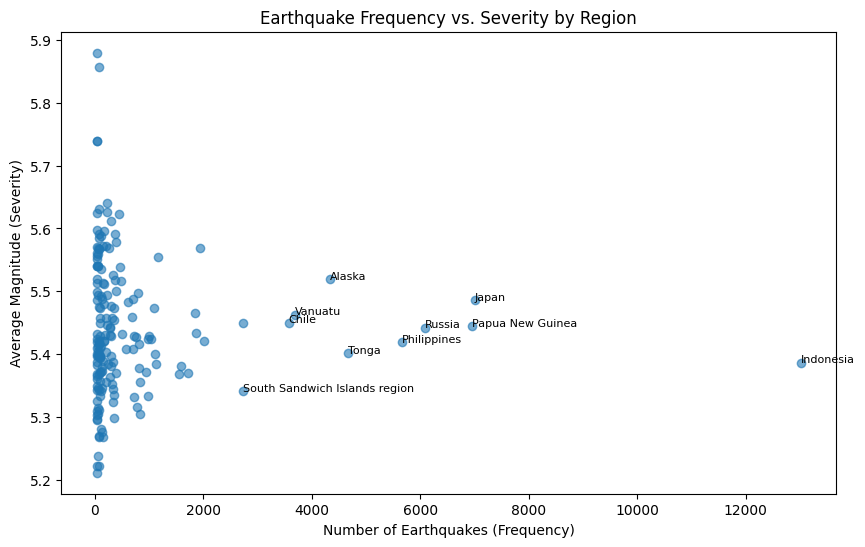

In [ ]:
#frequency vs. severity per region
import matplotlib.pyplot as plt

data = combined.collect()  # [(region, (count, avg_mag)), ...]
regions = [x[0] for x in data]
counts = [x[1][0] for x in data]
avg_mags = [x[1][1] for x in data]

plt.figure(figsize=(10, 6))
plt.scatter(counts, avg_mags, alpha=0.6)
plt.xlabel("Number of Earthquakes (Frequency)")
plt.ylabel("Average Magnitude (Severity)")
plt.title("Earthquake Frequency vs. Severity by Region")

# Label the top 10
top10 = sorted(data, key=lambda x: -x[1][0])[:10]
for region, (count, mag) in top10:
    plt.annotate(region, (count, mag), fontsize=8)

plt.show()

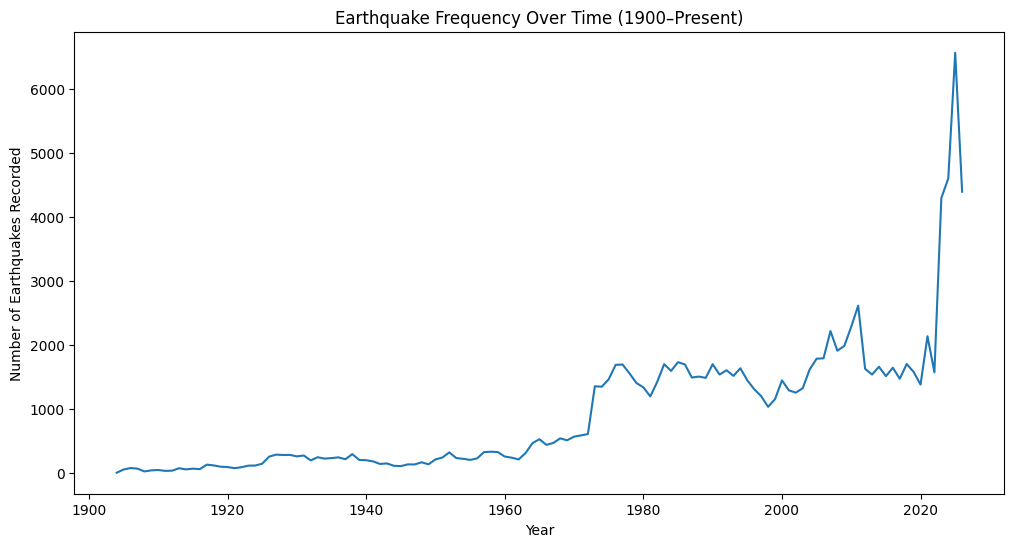

In [ ]:
#number of earthquakes per year
year_freq = rdd.map(lambda x: (x[0], 1)) \
               .reduceByKey(lambda a, b: a + b)

# Sort by year
year_freq_sorted = year_freq.sortByKey().collect()

years = [x[0] for x in year_freq_sorted]
counts = [x[1] for x in year_freq_sorted]

plt.figure(figsize=(12, 6))
plt.plot(years, counts)
plt.xlabel("Year")
plt.ylabel("Number of Earthquakes Recorded")
plt.title("Earthquake Frequency Over Time (1900–Present)")
plt.show()

This apparent rise in recorded earthquake frequency over time likely reflects improvements in global seismograph coverage and detection sensitivity rather than an actual increase in seismic activity.

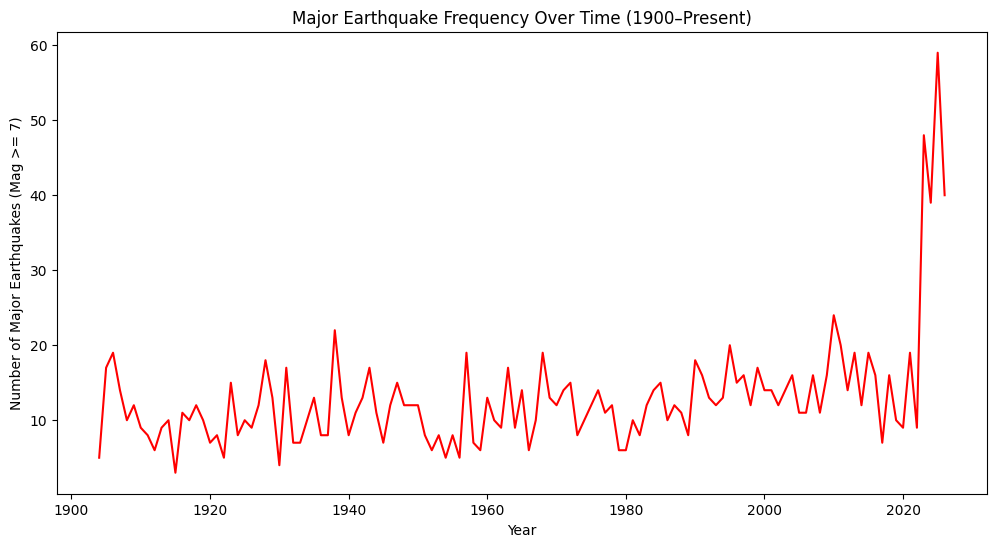

Total major earthquakes: 1588


In [ ]:
# frequency of major earthquakes (mag >= 7) per year
major_quakes = rdd.filter(lambda x: x[3] >= 7.0)

major_year_freq = major_quakes.map(lambda x: (x[0], 1)) \
                               .reduceByKey(lambda a, b: a + b) \
                               .sortByKey()

major_data = major_year_freq.collect()
years_major = [x[0] for x in major_data]
counts_major = [x[1] for x in major_data]

plt.figure(figsize=(12, 6))
plt.plot(years_major, counts_major, color="red")
plt.xlabel("Year")
plt.ylabel("Number of Major Earthquakes (Mag >= 7)")
plt.title("Major Earthquake Frequency Over Time (1900–Present)")
plt.show()

print("Total major earthquakes:", major_quakes.count())

There's an unexplained spike in major earthquakes in the last few years that this dataset alone can't fully explain, and would need further investigation to understand.

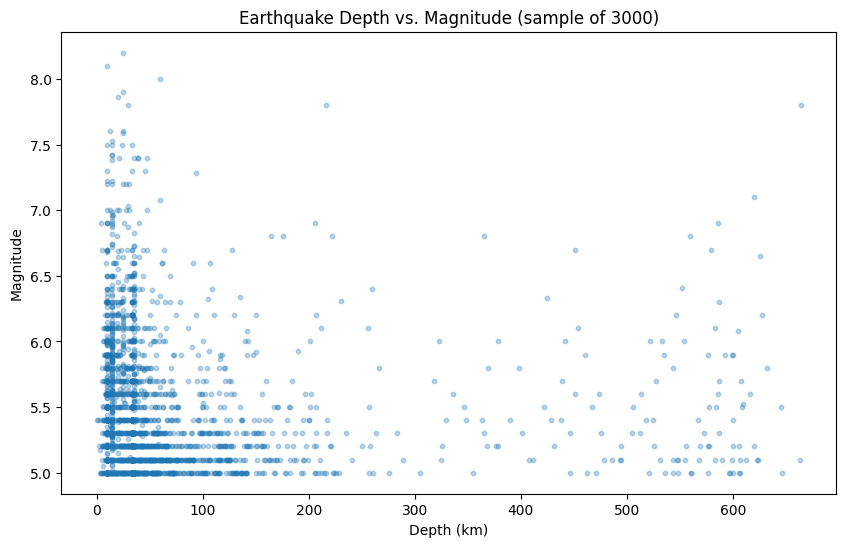

Correlation between depth and magnitude: -0.007


In [ ]:
#depth vs mag
#sampled data
sample = rdd.map(lambda x: (x[2], x[3])).takeSample(False, 3000, seed=42)

depths = [x[0] for x in sample]
mags = [x[1] for x in sample]

plt.figure(figsize=(10, 6))
plt.scatter(depths, mags, alpha=0.3, s=10)
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.title("Earthquake Depth vs. Magnitude (sample of 3000)")
plt.show()

#correlation
import numpy as np
all_depths_mags = rdd.map(lambda x: (x[2], x[3])).collect()
depths_full = np.array([x[0] for x in all_depths_mags])
mags_full = np.array([x[1] for x in all_depths_mags])
correlation = np.corrcoef(depths_full, mags_full)[0, 1]
print("Correlation between depth and magnitude:", round(correlation, 3))

Depth and magnitude show no meaningful correlation (r ≈ -0.007), indicating that earthquake strength is not systematically related to how deep the rupture occurs, shallow and deep earthquakes alike span a similar range of magnitudes.

In [ ]:
#Compute average lat/lon per region
geo_data = df_clean[['region', 'latitude', 'longitude']].values.tolist()
geo_rdd = sc.parallelize(geo_data)

region_coords = geo_rdd.map(lambda x: (x[0], (x[1], x[2], 1))) \
                        .reduceByKey(lambda a, b: (a[0]+b[0], a[1]+b[1], a[2]+b[2])) \
                        .map(lambda x: (x[0], (x[1][0]/x[1][2], x[1][1]/x[1][2])))

print(region_coords.take(3))

[('Bulgaria', (42.256565217391305, 24.891565217391303)), ('Russia', (49.75144979471177, 151.75244953194266)), ('China', (35.007960466377426, 94.5343364425163))]


In [ ]:
#Join hotspot ranking (count, avg_mag) with coordinates
hotspots = combined.join(region_coords)  # (region, ((count, avg_mag), (lat, lon)))
hotspot_list = hotspots.collect()

# Print top 10 ranked by frequency
top10_hotspots = sorted(hotspot_list, key=lambda x: -x[1][0][0])[:10]
print(f"{'Region':<30}{'Count':<10}{'Avg Mag':<10}")
for region, ((count, avg_mag), (lat, lon)) in top10_hotspots:
    print(f"{region:<30}{count:<10}{round(avg_mag,2):<10}")

Region                        Count     Avg Mag   
Indonesia                     13020     5.39      
Japan                         7009      5.49      
Papua New Guinea              6951      5.44      
Russia                        6089      5.44      
Philippines                   5667      5.42      
Tonga                         4672      5.4       
Alaska                        4339      5.52      
Vanuatu                       3685      5.46      
Chile                         3572      5.45      
South Sandwich Islands region 2723      5.34      


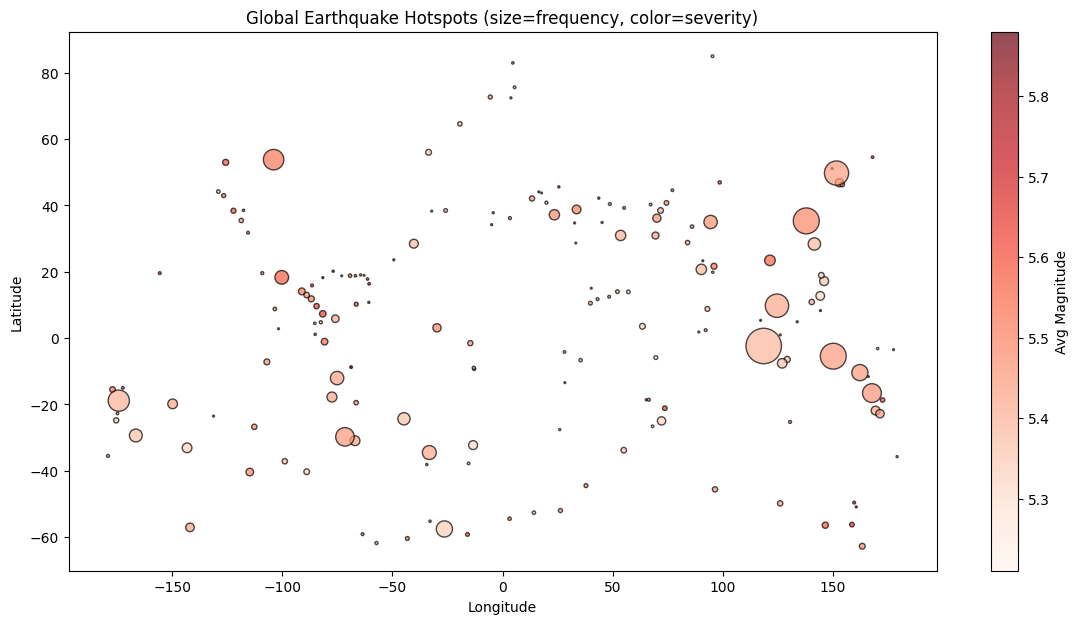

In [ ]:
#Plot hotspots on a world map (size=frequency, color=severity)
lons = [x[1][1][1] for x in hotspot_list]
lats = [x[1][1][0] for x in hotspot_list]
counts = [x[1][0][0] for x in hotspot_list]
mags = [x[1][0][1] for x in hotspot_list]

plt.figure(figsize=(14, 7))
sc_plot = plt.scatter(lons, lats, s=[c/20 for c in counts], c=mags, cmap='Reds', alpha=0.7, edgecolors='black')
plt.colorbar(sc_plot, label="Avg Magnitude")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Earthquake Hotspots (size=frequency, color=severity)")
plt.show()

**Findings:**

**Hotspots:**

Indonesia, Japan, Papua New Guinea, Russia, and the Philippines have the most earthquakes — all along the Pacific Ring of Fire.


**Frequent ≠ severe:**

These hotspot regions actually have only moderate average magnitudes (~5.4–5.5). Regions with the highest average magnitudes just had one massive historic quake (like the 1960 Chile quake, mag 9.5) skewing their average — not a real pattern of severity.


**The "rise" in earthquakes is mostly better detection:**

Total recorded quakes per year jumped ~100x since 1900, but that's largely because seismograph coverage improved, not because the Earth got more active.



**Major quakes stayed stable:**

Looking only at magnitude ≥7 quakes (which older equipment could still detect), the rate stayed roughly flat over the century — supporting that the earlier trend was a detection artifact. A recent spike in the last few years is unexplained and needs further study.


**Depth and magnitude aren't related:**

Correlation was basically zero — a shallow quake can be just as strong as a deep one.

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np
from matplotlib.figure import Figure
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib import cm

# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
df_g = pd.read_csv("earthquakes_clean.csv")
df_g["time"] = pd.to_datetime(df_g["time"], format="mixed")
df_g["year"] = df_g["time"].dt.year
regions_list = sorted(df_g["region"].unique().tolist())
DEFAULT_REGION = "Indonesia" if "Indonesia" in regions_list else regions_list[0]

# ----------------------------------------------------------------------------
# Visual tokens (one palette shared by the UI and the charts)
# ----------------------------------------------------------------------------
INK = "#17262e"        # basalt: text, axes
MUTED = "#6b7b84"      # secondary text
PAPER = "#f1f4f5"      # page background
CARD = "#ffffff"
GRID = "#dde4e7"
BLUE = "#1f5f7a"       # frequency (counts)
# magnitude ramp: calm -> severe. Used wherever colour encodes magnitude.
MAG_CMAP = LinearSegmentedColormap.from_list(
    "mag", ["#2a9d8f", "#e9c46a", "#e76f51", "#9b1d20"]
)
COUNT_CMAP = LinearSegmentedColormap.from_list("count", ["#8fb8c9", "#1f5f7a", "#0f3547"])

CSS = """
@import url('https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:wght@600;700;800&family=Manrope:wght@400;500;600;700&display=swap');

.gradio-container { max-width: 1180px !important; margin: 0 auto !important;
                    font-family: 'Manrope', system-ui, sans-serif !important; }
body, .gradio-container { background: #f1f4f5 !important; }

/* masthead */
.masthead { padding: 28px 8px 8px; }
.masthead h1 { font-family: 'Bricolage Grotesque', sans-serif; font-weight: 800;
               font-size: 2.6rem; letter-spacing: -0.02em; color: #17262e; margin: 0; }
.masthead p  { color: #6b7b84; font-size: 1.02rem; margin: 6px 0 0; max-width: 62ch; line-height: 1.55; }

/* headline numbers */
.kpis { display: grid; grid-template-columns: repeat(4, 1fr); gap: 14px; margin: 18px 0 6px; }
.kpi  { background: #fff; border-radius: 14px; padding: 16px 18px; border: 1px solid #dde4e7; }
.kpi b { display: block; font-family: 'Bricolage Grotesque', sans-serif; font-size: 1.8rem;
         color: #17262e; line-height: 1.1; }
.kpi span { color: #6b7b84; font-size: .86rem; }
.kpi.accent { border-left: 5px solid #e76f51; }

/* tabs */
.tab-nav, div[role="tablist"] { border-bottom: 1px solid #dde4e7 !important; }
button[role="tab"] { font-family: 'Manrope', sans-serif !important; font-weight: 600 !important;
                     color: #6b7b84 !important; font-size: .98rem !important; }
button[role="tab"][aria-selected="true"] { color: #17262e !important;
                     border-bottom: 3px solid #1f5f7a !important; }

/* panels */
.side { background: #fff; border: 1px solid #dde4e7; border-radius: 14px; padding: 20px !important; }
.side h3 { font-family: 'Bricolage Grotesque', sans-serif; color: #17262e; margin-top: 0; }
.side p  { color: #6b7b84; line-height: 1.55; }
.chart { background: #fff; border: 1px solid #dde4e7 !important; border-radius: 14px; padding: 6px; }

/* ranked lists */
.rank { list-style: none; padding: 0; margin: 14px 0 0; }
.rank li { display: flex; justify-content: space-between; align-items: center; gap: 10px;
           padding: 9px 0; border-top: 1px solid #eaeff1; color: #17262e; font-size: .95rem; }
.rank li:first-child { border-top: none; }
.rank .val { font-weight: 700; font-variant-numeric: tabular-nums; }
.rank .dot { width: 10px; height: 10px; border-radius: 50%; flex: none; }
.rank .name { flex: 1; }

/* region stat tiles */
.tiles { display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-top: 14px; }
.tile { background: #f1f4f5; border-radius: 12px; padding: 12px 14px; }
.tile b { display: block; font-family: 'Bricolage Grotesque', sans-serif; font-size: 1.45rem; color: #17262e; }
.tile span { font-size: .8rem; color: #6b7b84; }
.empty { color: #6b7b84; padding: 8px 0; }

/* Gradio's own prose/dark-mode styles can turn text near-white; pin our colours */
.side, .side .prose, .side .prose * { color: #17262e !important; }
.side p, .side p * { color: #6b7b84 !important; }
.side p b, .side p strong { color: #17262e !important; }
.rank li, .rank li * { color: #17262e !important; }
.tile b { color: #17262e !important; }
.tile span { color: #6b7b84 !important; }
.kpi b { color: #17262e !important; }
.kpi span { color: #6b7b84 !important; }
.masthead h1 { color: #17262e !important; }
.masthead p { color: #6b7b84 !important; }
.empty { color: #6b7b84 !important; }
.rank .dot { background-clip: padding-box; }

@media (max-width: 760px) { .kpis { grid-template-columns: 1fr 1fr; } .masthead h1 { font-size: 2rem; } }
"""

theme = gr.themes.Base(
    primary_hue=gr.themes.colors.cyan,
    neutral_hue=gr.themes.colors.slate,
    radius_size=gr.themes.sizes.radius_lg,
    font=[gr.themes.GoogleFont("Manrope"), "system-ui", "sans-serif"],
).set(
    button_primary_background_fill="#1f5f7a",
    button_primary_background_fill_hover="#17495f",
    button_primary_text_color="white",
    slider_color="#1f5f7a",
    block_border_width="0px",
    block_shadow="none",
)

# ----------------------------------------------------------------------------
# Chart helpers
# ----------------------------------------------------------------------------
def new_fig(w=9.5, h=5.4):
    fig = Figure(figsize=(w, h), dpi=130, facecolor=CARD)
    ax = fig.subplots()
    ax.set_facecolor(CARD)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.xaxis.label.set_color(MUTED)
    ax.yaxis.label.set_color(MUTED)
    return fig, ax


def title(ax, text, sub=None):
    ax.set_title(text, loc="left", fontsize=14, fontweight="bold", color=INK, pad=26 if sub else 14)
    if sub:
        ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=9.5, color=MUTED, va="bottom")


def message_fig(text):
    fig, ax = new_fig()
    ax.axis("off")
    ax.text(0.5, 0.5, text, ha="center", va="center", fontsize=12, color=MUTED, transform=ax.transAxes)
    return fig


def ranked_list(names, values, colors, fmt):
    rows = "".join(
        f"<li><span class='dot' style='background:{c}'></span>"
        f"<span class='name'>{n}</span><span class='val'>{fmt(v)}</span></li>"
        for n, v, c in zip(names, values, colors)
    )
    return f"<ul class='rank'>{rows}</ul>"


def hbar(ax, labels, values, colors, fmt):
    """Horizontal bars, largest on top, with value labels at the bar ends."""
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, color=colors, height=0.68, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, color=INK, fontsize=10)
    ax.grid(True, axis="x", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    span = max(values) if len(values) else 1
    for yi, v in zip(y, values):
        ax.text(v + span * 0.012, yi, fmt(v), va="center", fontsize=9, color=INK, fontweight="bold")


# ----------------------------------------------------------------------------
# Static pieces
# ----------------------------------------------------------------------------
def header_html():
    n = len(df_g)
    y0, y1 = int(df_g["year"].min()), int(df_g["year"].max())
    return f"""
    <div class='masthead'>
      <h1>Global Earthquake Atlas</h1>
      <p>Explore {y1 - y0 + 1} years of cleaned seismic records: where the ground moves most,
      where it moves hardest, and how any single region has changed over time.</p>
    </div>
    <div class='kpis'>
      <div class='kpi'><b>{n:,}</b><span>earthquakes recorded</span></div>
      <div class='kpi'><b>{df_g['region'].nunique():,}</b><span>regions covered</span></div>
      <div class='kpi'><b>{y0}&ndash;{y1}</b><span>observation period</span></div>
      <div class='kpi accent'><b>M {df_g['mag'].max():.1f}</b><span>strongest on record</span></div>
    </div>
    """


# ----------------------------------------------------------------------------
# Tab 1: frequency
# ----------------------------------------------------------------------------
def plot_frequency():
    freqs = df_g["region"].value_counts().head(15)
    norm = Normalize(vmin=freqs.min() * 0.6, vmax=freqs.max())
    colors = [COUNT_CMAP(norm(v)) for v in freqs.values]

    fig, ax = new_fig()
    hbar(ax, freqs.index.tolist(), freqs.values, colors, lambda v: f"{int(v):,}")
    title(ax, "Most active regions", "Number of registered earthquakes, top 15")
    ax.set_xlabel("Earthquakes", labelpad=8)
    ax.set_xlim(0, freqs.max() * 1.12)
    fig.tight_layout()

    top = freqs.head(5)
    share = top.sum() / len(df_g) * 100
    html = (
        f"<h3 style='margin:18px 0 0'>Top 5</h3>"
        + ranked_list(top.index, top.values, [COUNT_CMAP(norm(v)) for v in top.values], lambda v: f"{int(v):,}")
        + f"<p style='margin-top:12px'>These five regions account for <b>{share:.0f}%</b> of all recorded events.</p>"
    )
    return fig, html


# ----------------------------------------------------------------------------
# Tab 2: severity
# ----------------------------------------------------------------------------
def plot_severity(min_quakes):
    counts = df_g["region"].value_counts()
    valid = counts[counts >= min_quakes].index
    d = df_g[df_g["region"].isin(valid)]

    if d.empty:
        return (
            message_fig("No regions match.\nLower the minimum to include more of them."),
            f"<p class='empty'>No regions have at least {int(min_quakes)} earthquakes.</p>",
        )

    sev = d.groupby("region")["mag"].mean().sort_values(ascending=False).head(15)
    norm = Normalize(vmin=5.0, vmax=max(sev.max(), 6.5))
    colors = [MAG_CMAP(norm(v)) for v in sev.values]

    fig, ax = new_fig()
    hbar(ax, sev.index.tolist(), sev.values, colors, lambda v: f"{v:.2f}")
    title(ax, "Regions with the strongest average quake",
          f"Average magnitude, top 15 regions with at least {int(min_quakes)} events")
    ax.set_xlabel("Average magnitude (M)", labelpad=8)
    ax.set_xlim(max(0, min(5.0, sev.min() - 0.3)), sev.max() + 0.25)
    fig.colorbar(cm.ScalarMappable(norm=norm, cmap=MAG_CMAP), ax=ax, pad=0.02, fraction=0.025,
                 label="Magnitude").outline.set_visible(False)
    fig.tight_layout()

    top = sev.head(5)
    html = (
        f"<h3 style='margin:18px 0 0'>Top 5</h3>"
        + ranked_list(top.index, top.values, [MAG_CMAP(norm(v)) for v in top.values], lambda v: f"M {v:.2f}")
        + f"<p style='margin-top:12px'>{len(valid)} regions meet the minimum.</p>"
    )
    return fig, html


# ----------------------------------------------------------------------------
# Tab 3: region lookup
# ----------------------------------------------------------------------------
def plot_region_lookup(selected_region):
    r = df_g[df_g["region"] == selected_region]
    if r.empty:
        return message_fig(f"No data for {selected_region}"), f"<p class='empty'>No data for {selected_region}.</p>"

    count, avg_mag, max_mag, avg_depth = len(r), r["mag"].mean(), r["mag"].max(), r["depth"].mean()
    yearly = r.groupby("year")["mag"].agg(["mean", "size"])

    fig, ax = new_fig()
    ax.plot(yearly.index, yearly["mean"], color=GRID, linewidth=2, zorder=2)
    sizes = 25 + 140 * (yearly["size"] / yearly["size"].max())
    sc = ax.scatter(yearly.index, yearly["mean"], s=sizes, c=yearly["mean"], cmap=MAG_CMAP,
                    norm=Normalize(5.0, 7.0), edgecolor="white", linewidth=1, zorder=3)
    ax.axhline(avg_mag, color=MUTED, linestyle=(0, (4, 4)), linewidth=1, zorder=1)
    ax.text(ax.get_xlim()[1], avg_mag, f" all-time mean {avg_mag:.2f}", va="center", fontsize=8.5, color=MUTED)
    title(ax, f"{selected_region}: average magnitude by year",
          "Dot size shows how many earthquakes that year; colour shows magnitude")
    ax.set_xlabel("Year", labelpad=8)
    ax.set_ylabel("Average magnitude (M)", labelpad=8)
    ax.grid(True, axis="y", color=GRID, linewidth=0.8, zorder=0)
    fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.025, label="Magnitude").outline.set_visible(False)
    fig.tight_layout()

    html = f"""
    <h3 style='margin:18px 0 0'>{selected_region}</h3>
    <div class='tiles'>
      <div class='tile'><b>{count:,}</b><span>earthquakes</span></div>
      <div class='tile'><b>{avg_mag:.2f}</b><span>average magnitude</span></div>
      <div class='tile'><b>{max_mag:.1f}</b><span>strongest (M)</span></div>
      <div class='tile'><b>{avg_depth:.0f} km</b><span>average depth</span></div>
    </div>
    """
    return fig, html


# ----------------------------------------------------------------------------
# Layout
# ----------------------------------------------------------------------------
with gr.Blocks(title="Global Earthquake Atlas", theme=theme, css=CSS) as demo:
    gr.HTML(header_html())

    with gr.Tabs():
        with gr.TabItem("Hotspots"):
            with gr.Row(equal_height=False):
                with gr.Column(scale=1, elem_classes="side"):
                    gr.Markdown("### Where it happens most\nRegions with the most registered earthquakes. "
                                "They tend to sit along tectonic plate boundaries.")
                    freq_text = gr.HTML()
                with gr.Column(scale=2):
                    freq_plot = gr.Plot(show_label=False, elem_classes="chart")

        with gr.TabItem("Severity"):
            with gr.Row(equal_height=False):
                with gr.Column(scale=1, elem_classes="side"):
                    gr.Markdown("### Where it hits hardest\nRegions with few records can skew an average. "
                                "Raise the minimum to focus on places where strong quakes keep recurring.")
                    severity_slider = gr.Slider(1, 150, value=30, step=5,
                                                label="Minimum earthquakes per region")
                    severity_text = gr.HTML()
                with gr.Column(scale=2):
                    severity_plot = gr.Plot(show_label=False, elem_classes="chart")

        with gr.TabItem("Region finder"):
            with gr.Row(equal_height=False):
                with gr.Column(scale=1, elem_classes="side"):
                    gr.Markdown("### Look at one region\nPick a country or region to see its key numbers "
                                "and how its average magnitude has moved year by year.")
                    region_dropdown = gr.Dropdown(choices=regions_list, value=DEFAULT_REGION,
                                                  label="Region", filterable=True)
                    region_stats = gr.HTML()
                with gr.Column(scale=2):
                    region_plot = gr.Plot(show_label=False, elem_classes="chart")

    # Render every tab on load so nothing starts empty
    demo.load(plot_frequency, None, [freq_plot, freq_text])
    demo.load(plot_severity, severity_slider, [severity_plot, severity_text])
    demo.load(plot_region_lookup, region_dropdown, [region_plot, region_stats])

    severity_slider.change(plot_severity, severity_slider, [severity_plot, severity_text])
    region_dropdown.change(plot_region_lookup, region_dropdown, [region_plot, region_stats])

demo.launch(share=True, debug=True)

/tmp/ipykernel_3024/1956351892.py:288: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Global Earthquake Atlas", theme=theme, css=CSS) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://53b4e223df372ad5a3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
